In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We present a novel approach to the problem of ...,0.3311,0.0600,0.1987,0.8587,0.8111,0.8342,2,8,8,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,We present a novel approach to the problem of ...,0.1934,0.0365,0.1269,0.8555,0.7990,0.8263,1,8,8,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,We consider the problem of learning a mixture ...,0.2442,0.0471,0.1279,0.8222,0.8268,0.8245,1,9,9,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


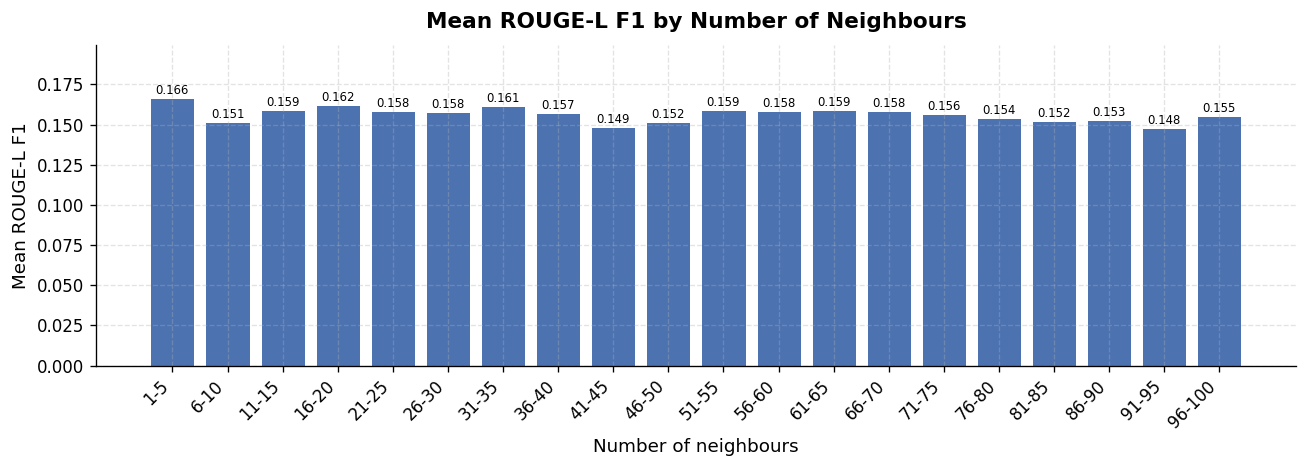

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

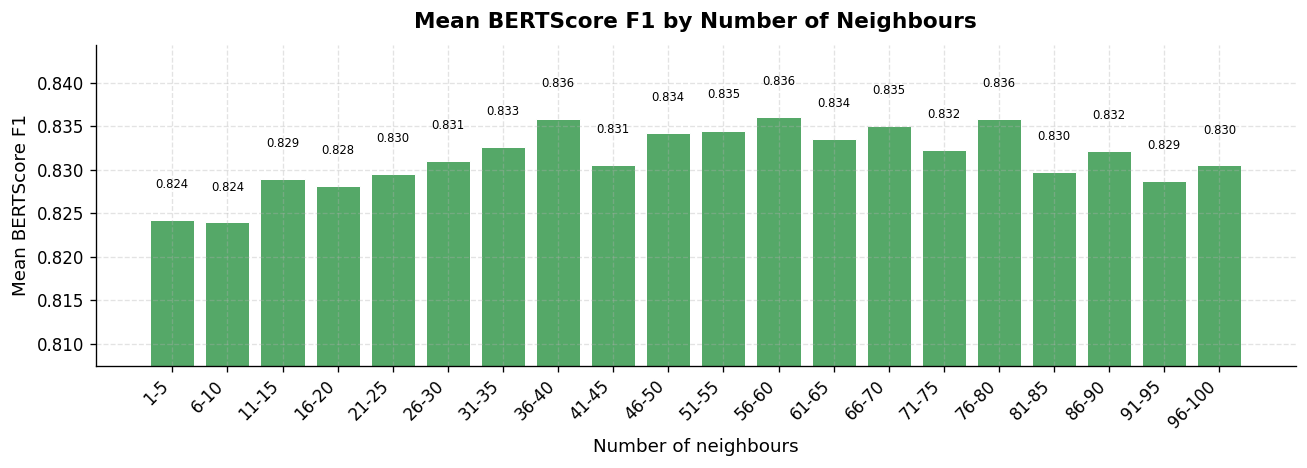

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

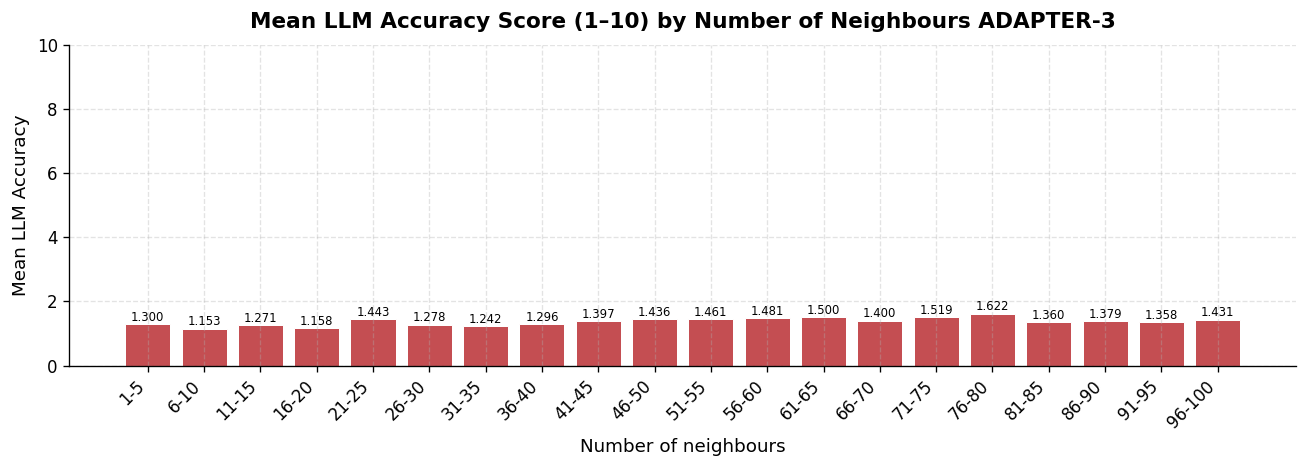

1.3767195767195768
1.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

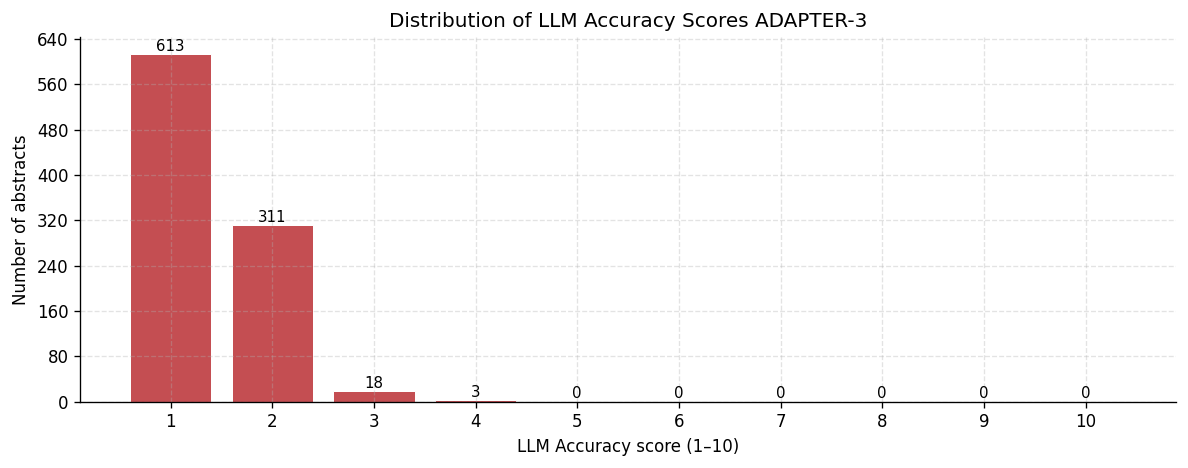

llm_accuracy
1     613
2     311
3      18
4       3
5       0
6       0
7       0
8       0
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

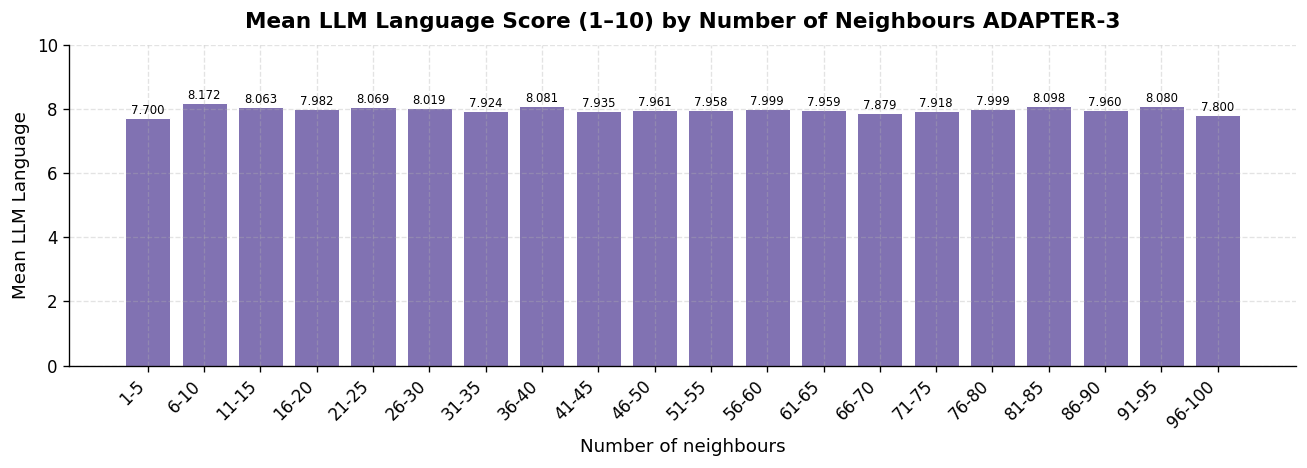

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

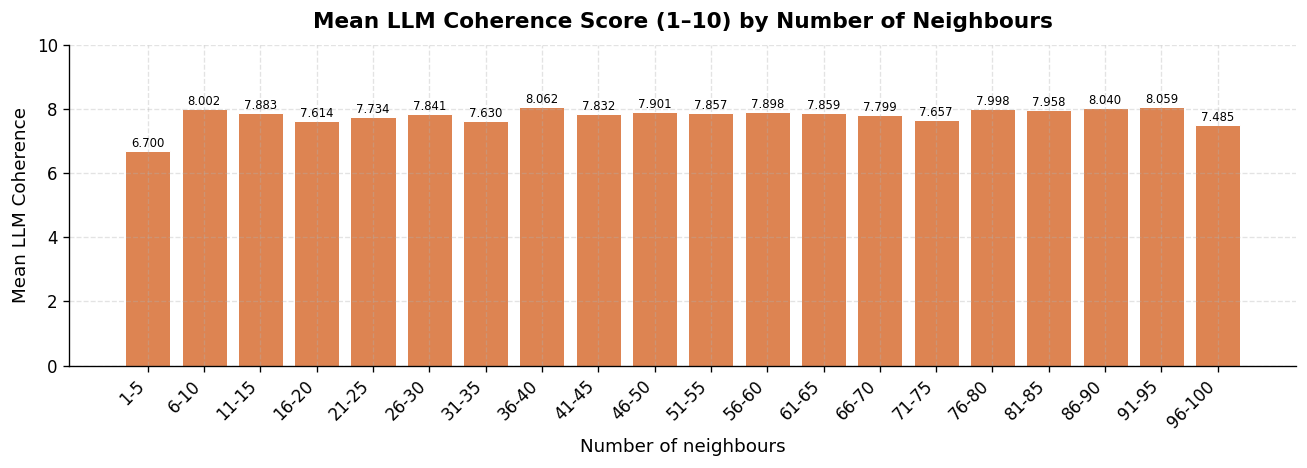

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

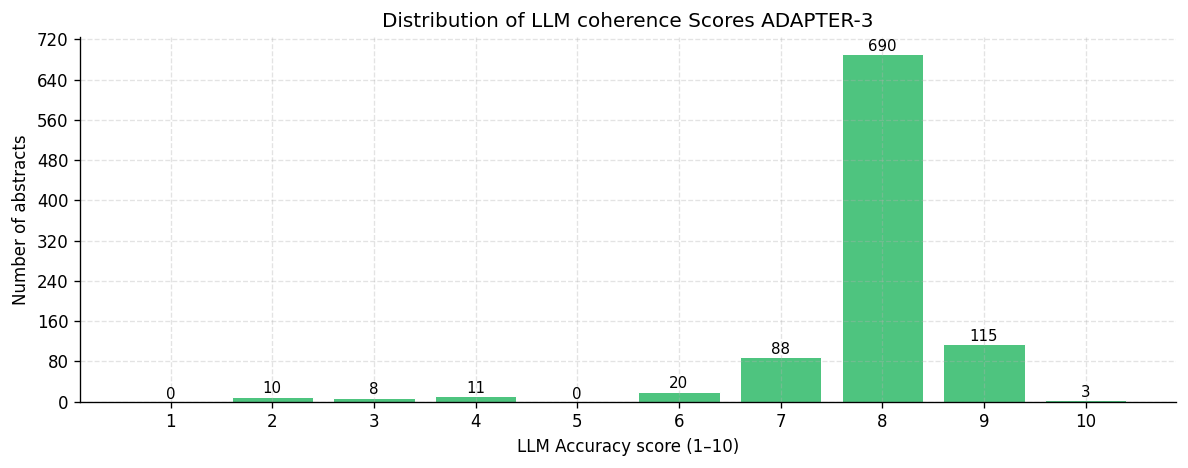

llm_coherence
1       0
2      10
3       8
4      11
5       0
6      20
7      88
8     690
9     115
10      3
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 10 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      1.3767
Mean llm_accuracy (excluding 1,2): 1.3807


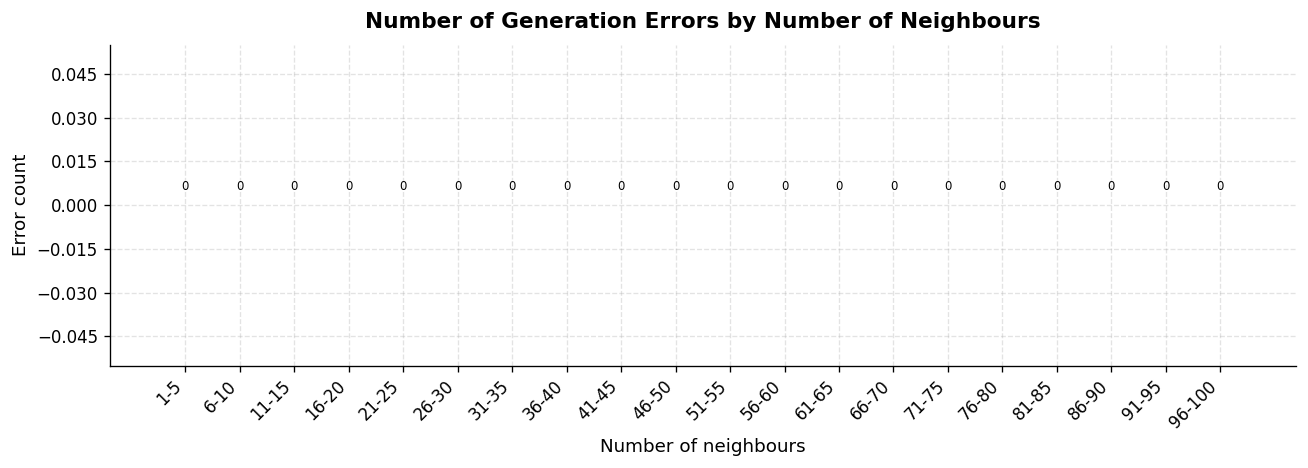

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_50769/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,6250,"We propose a kernel regression method to predict a target signal lying over a graph when an input observation is given. The input and the output could be two different physical quantities. In particular, the input may not be a graph signal at all or it could be agnostic to an underlying graph. We use a training dataset to learn the proposed regression model by formulating it as a convex optimization problem, where we use a graph-Laplacian based regularization to enforce that the predicted target is a graph signal. Once the model is learnt, it can be directly used on a large number of test data points one-by-one independently to predict the corresponding targets. Our approach employs kernels between the various input observations, and as a result the kernels are not restricted to be functions of the graph adjacency/Laplacian matrix. We show that the proposed kernel regression exhibits a smoothing effect, while simultaneously achieving noise-reduction and graph-smoothness. We then extend our method to the case when the underlying graph may not be known apriori, by simultaneously learning an underlying graph and the regression coefficients. Using extensive experiments, we show that our method provides a good prediction performance in adverse conditions, particularly when the training data is limited in size and is noisy. In graph signal reconstruction experiments, our method is shown to provide a good performance even for a highly under-determined subsampling.","We present a new approach to the problem of learning a deep neural network from scratch, without using any pre-trained weights. Our approach is based on the observation that the weights of a neural network can be initialized to a set of values that are close to the values that will be learned during training. We show that this can be achieved by initializing the weights to a set of values that are close to the values that will be learned during training. We show that this can be achieved by initializing the weights to a set of values that are close to the values that will be learned during training.",2
1,28575,"Local differential privacy (LDP) can provide each user with strong privacy guarantees under untrusted data curators while ensuring accurate statistics derived from privatized data. Due to its powerfulness, LDP has been widely adopted to protect privacy in various tasks (e.g., heavy hitters discovery, probability estimation) and systems (e.g., Google Chrome, Apple iOS). Although ${\epsilon}$-LDP has been proposed for many years, the more general notion of $({\epsilon}, {\delta})$-LDP has only been studied in very few papers, which mainly consider mean estimation for numeric data. Besides, prior solutions achieve $({\epsilon}, {\delta})$-LDP by leveraging Gaussian mechanism, which leads to low accuracy of the aggregated results. In this paper, we propose novel mechanisms that achieve $({\epsilon}, {\delta})$-LDP with high utility in data analytics and machine learning. Specifically, we first design $({\epsilon}, {\delta})$-LDP algorithms for collecting multi-dimensional numeric data, which can ensure higher accuracy than the optimal Gaussian mechanism while guaranteeing strong privacy for each user. Then, we investigate different local protocols for categorical attributes under $({\epsilon}, {\delta})$-LDP. Furthermore, we conduct theoretical analysis on the error bound and variance of the proposed algorithms. Experimental results on real and synthetic datasets demonstrate the high data utility of our proposed algorithms on both simple data statistics and complex machine learning models.","We consider the problem of learning a mixture of two Gaussians in high dimensions, given a set of samples. We show that a simple algorithm based on the method of moments can provably learn the parameters of the mixture, in time polynomial in the dimension, given a set of samples whose size is polynomial in the dime

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_50769/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,61777,"Given the recent surge in developments of deep learning, this paper provides a review of the state-of-the-art deep learning techniques for audio signal processing. Speech, music, and environmental sound processing are considered side-by-side, in order to point out similarities and differences between the domains, highlighting general methods, problems, key references, and potential for cross fertilization between areas. The dominant feature representations (in particular, log-mel spectra and raw waveform) and deep learning models are reviewed, including convolutional neural networks, variants of the long short-term memory architecture, as well as more audio-specific neural network models. Subsequently, prominent deep learning application areas are covered, i.e., audio recognition (automatic speech recognition, music information retrieval, environmental sound detection, localization and tracking) and synthesis and transformation (source separation, audio enhancement, generative models for speech, sound, and music synthesis). Finally, key issues and future questions regarding deep learning applied to audio signal processing are identified.","We present a novel approach to the problem of learning a deep neural network for a given task, by using a reinforcement learning agent to control the learning process. The agent is trained to select the most effective learning algorithm from a large space of possible algorithms, and to adaptively choose the best algorithm for each stage of the learning process. We show that this approach can be used to learn a deep neural network for the MNIST classification task, and that the agent learns to use a novel algorithm that outperforms the best known algorithm for this task.",1
1,78941,"The aim of this work is learning to reshape the object in an input image to an arbitrary new shape, by just simply providing a single reference image with an object instance in the desired shape. We propose a new Generative Adversarial Network (GAN) architecture for such an object reshaping problem, named ReshapeGAN. The network can be tailored for handling all kinds of problem settings, including both within-domain (or single-dataset) reshaping and cross-domain (typically across mutiple datasets) reshaping, with paired or unpaired training data. The appearance of the input object is preserved in all cases, and thus it is still identifiable after reshaping, which has never been achieved as far as we are aware. We present the tailored models of the proposed ReshapeGAN for all the problem settings, and have them tested on 8 kinds of reshaping tasks with 13 different datasets, demonstrating the ability of ReshapeGAN on generating convincing and superior results for object reshaping. To the best of our knowledge, we are the first to be able to make one GAN framework work on all such object reshaping tasks, especially the cross-domain tasks on handling multiple diverse datasets. We present here both ablation studies on our proposed ReshapeGAN models and comparisons with the state-of-the-art models when they are made comparable, using all kinds of applicable metrics that we are aware of.",We present a novel approach to the problem of learning a deep neural network for the task of image classification. Our approach is based on the idea of using a reinforcement learning agent to learn a policy for selecting the best hyperparameters for training a deep neural network. We show that our approach is able to learn a policy that outperforms the best known hand-designed policy for training a deep neural network on the CIFAR-10 dataset.,1
2,167821,"We propose a novel theoretical framework that generalizes algorithms for hierarchical agglomerative clustering to weighted graphs with both attractive and repulsive interactions between the nodes. This framework defines GASP, a Generalized Algorithm for Signed graph Partitioning, and allows us to explore many combinati

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


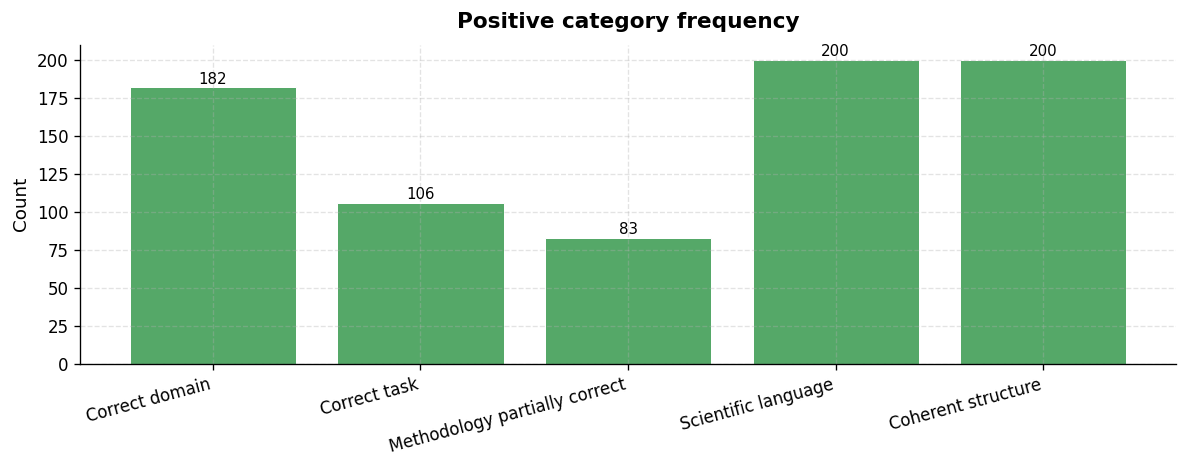

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()